In [1]:
import torch

In [32]:
single = torch.load('grad-fp32.new.pt')

In [33]:
single_dict = {}
for k, v in single[0]:
    single_dict[k] = single_dict.get(k, 0) + v.to(torch.float32)

In [34]:
rank_c = []
rank_b = []
for r in range(8):
    rank_b.append(torch.load(f'bf16-bug/rank{r}-grad.pt'))
    rank_c.append(torch.load(f'bf16/rank{r}-grad.pt'))

In [35]:
distri_dict_1_c = {}
distri_dict_2_c = {}
for r in [0,4]:
    for k, v in rank_c[r][0]:
        name = k.split('.')
        if r >= 4 and len(name) >= 5 and name[3] == 'layers':
            name[4] = str(int(name[4]) + 12)
        n = '.'.join(name)
        distri_dict_1_c[n] = v.to(torch.float32)
for r in [1,5]:
    for k, v in rank_c[r][0]:
        name = k.split('.')
        if r >= 4 and len(name) >= 5 and name[3] == 'layers':
            name[4] = str(int(name[4]) + 12)
        n = '.'.join(name)
        distri_dict_2_c[n] =  v.to(torch.float32)


In [36]:
distri_dict_1_b = {}
distri_dict_2_b = {}
for r in [0,4]:
    for k, v in rank_b[r][0]:
        name = k.split('.')
        if r >= 4 and len(name) >= 5 and name[3] == 'layers':
            name[4] = str(int(name[4]) + 12)
        n = '.'.join(name)
        distri_dict_1_b[n] = v.to(torch.float32)
for r in [1,5]:
    for k, v in rank_b[r][0]:
        name = k.split('.')
        if r >= 4 and len(name) >= 5 and name[3] == 'layers':
            name[4] = str(int(name[4]) + 12)
        n = '.'.join(name)
        distri_dict_2_b[n] =  v.to(torch.float32)


In [37]:
distri_dict_c = {}
for k in single_dict.keys():
    assert k in distri_dict_1_c.keys() and k in distri_dict_2_c.keys(), k
    single_shape = single_dict[k].shape
    tp1_shape = distri_dict_1_c[k].shape
    tp2_shape = distri_dict_2_c[k].shape
    assert tp1_shape == tp2_shape
    if single_shape == tp1_shape and single_shape == tp2_shape:  # replicate
        assert torch.all(distri_dict_1_c[k] == distri_dict_2_c[k]), k
        distri_dict_c[k] = distri_dict_1_c[k]
    else:
        if len(single_shape) == 1 or len(single_shape) == 2 and single_shape[0] == tp1_shape[0] + tp2_shape[0]:
            cat = torch.cat([distri_dict_1_c[k], distri_dict_2_c[k]], dim=0)
        elif len(single_shape) == 2 and single_shape[1] == tp1_shape[1] + tp2_shape[1]:
            cat = torch.cat([distri_dict_1_c[k], distri_dict_2_c[k]], dim=1)
        elif k == "module.module.embedding.word_embeddings.weight":
            cat = torch.cat([distri_dict_1_c[k], distri_dict_2_c[k]], dim=0)[:single_shape[0], :]
        else:
            assert False, k
        distri_dict_c[k] = cat

In [38]:
distri_dict_1_c.keys()

dict_keys(['module.module.embedding.word_embeddings.weight', 'module.module.embedding.position_embeddings.weight', 'module.module.decoder.layers.0.self_attention.linear_proj.weight', 'module.module.decoder.layers.0.self_attention.linear_proj.bias', 'module.module.decoder.layers.0.self_attention.linear_qkv.layer_norm_weight', 'module.module.decoder.layers.0.self_attention.linear_qkv.layer_norm_bias', 'module.module.decoder.layers.0.self_attention.linear_qkv.weight', 'module.module.decoder.layers.0.self_attention.linear_qkv.bias', 'module.module.decoder.layers.0.mlp.linear_fc1.layer_norm_weight', 'module.module.decoder.layers.0.mlp.linear_fc1.layer_norm_bias', 'module.module.decoder.layers.0.mlp.linear_fc1.weight', 'module.module.decoder.layers.0.mlp.linear_fc1.bias', 'module.module.decoder.layers.0.mlp.linear_fc2.weight', 'module.module.decoder.layers.0.mlp.linear_fc2.bias', 'module.module.decoder.layers.1.self_attention.linear_proj.weight', 'module.module.decoder.layers.1.self_attentio

In [39]:
distri_dict_b = {}
for k in single_dict.keys():
    assert k in distri_dict_1_b.keys() and k in distri_dict_2_b.keys(), k
    single_shape = single_dict[k].shape
    tp1_shape = distri_dict_1_b[k].shape
    tp2_shape = distri_dict_2_b[k].shape
    assert tp1_shape == tp2_shape
    if single_shape == tp1_shape and single_shape == tp2_shape:  # replicate
        assert torch.all(distri_dict_1_b[k] == distri_dict_2_b[k]), k
        distri_dict_b[k] = distri_dict_1_b[k]
    else:
        if len(single_shape) == 1 or len(single_shape) == 2 and single_shape[0] == tp1_shape[0] + tp2_shape[0]:
            cat = torch.cat([distri_dict_1_b[k], distri_dict_2_b[k]], dim=0)
        elif len(single_shape) == 2 and single_shape[1] == tp1_shape[1] + tp2_shape[1]:
            cat = torch.cat([distri_dict_1_b[k], distri_dict_2_b[k]], dim=1)
        elif k == "module.module.embedding.word_embeddings.weight":
            cat = torch.cat([distri_dict_1_b[k], distri_dict_2_b[k]], dim=0)[:single_shape[0], :]
        else:
            assert False, k
        distri_dict_b[k] = cat

In [40]:
single_dict, distri_dict_c, distri_dict_b;

In [41]:
single = single_dict['module.module.decoder.layers.23.mlp.linear_fc2.weight']
distri = distri_dict_c['module.module.decoder.layers.23.mlp.linear_fc2.weight']
bug = distri_dict_b['module.module.decoder.layers.23.mlp.linear_fc2.weight']


In [45]:
mask = torch.abs(single) > 1.2e-38
ss = single[mask]; dd = distri[mask]; bb = bug[mask]

In [46]:
rel = torch.abs(ss - dd) / torch.abs(ss)
a = rel.sort()[0]
brel = torch.abs(ss - bb) / torch.abs(ss)
b = brel.sort()[0]

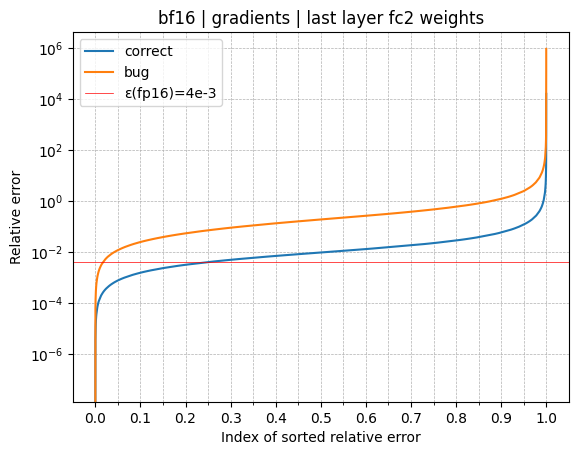

In [53]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
plt.plot(np.arange(len(a))/len(a), a.numpy())
plt.plot(np.arange(len(b))/len(b), b.numpy())
plt.axhline(y=4e-3, color='r', linestyle='-', linewidth=0.5, label='ε')
plt.yscale('log')
plt.legend(['correct', 'bug', 'ε(fp16)=4e-3'])
plt.xlabel('Index of sorted relative error')
plt.ylabel('Relative error')
plt.title('bf16 | gradients | last layer fc2 weights')
# change figure size
# plt.gcf().set_size_inches(8, 6)
# 自定义主刻度和次刻度
plt.gca().xaxis.set_major_locator(ticker.MultipleLocator(0.1))  # 每 1 个单位一个主刻度
plt.gca().xaxis.set_minor_locator(ticker.MultipleLocator(0.05))  # 每 0.2 个单位一个次刻度
plt.gca().yaxis.set_major_locator(ticker.LogLocator(base=10.0, numticks=10))
plt.gca().yaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=10))
# 格式化刻度标签
plt.gca().yaxis.set_major_formatter(ticker.LogFormatterMathtext())
# 显示网格
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.show()